# Sleeper projections vs. actual results, 2022-2025

**Question.** How good are Sleeper's weekly fantasy projections, and where do they go wrong: recurring
biases, segments where they underperform, anomalies?

**Data.** Sleeper's weekly projections (provider: Rotowire) and actual stats (provider: Sportradar), regular
season weeks 1-18, QB/RB/WR/TE. Both projections and actuals are scored from their stat lines with the league's
scoring (full PPR); section 1b shows why Sleeper's stored `pts_ppr` can't be used. Joined with nflverse
schedules (Vegas spread/total, roof, weather) and the official weekly injury report. One row = a player Sleeper
projected above 0 points in a week. Built by `common.load_frame`.

**Scope.** 2022-2025 (4 seasons, ~24k player-games). 2021 is loaded only as history for the trailing baselines:
its stored projections have no timestamps and are missing for players who left the league soon after
(Brady, Roethlisberger, A. Brown; see section 9). 2026 (weeks 1-7) is kept out on purpose: it is the
out-of-time test set for the model in `03_model.ipynb`, and looking at it here would leak into modeling choices.

**Residual convention.** `resid = proj - act`. Positive = Sleeper projected too high (over-projection).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests

from common import load_frame, metrics, POSITIONS, COMPONENTS

FIG = Path("figures")
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 160)

df_all = load_frame(range(2021, 2026))  # 2021 kept only as history for trailing baselines
df = df_all[df_all.season >= 2022].copy()
print(df.shape)
df.groupby(["season", "position"]).size().unstack()

(24168, 61)


position,QB,RB,TE,WR
season,,,,
2022,549,1655,1519,2454
2023,550,1574,1315,2509
2024,559,1560,1327,2504
2025,547,1572,1451,2523


## 1. Is the stored projection a fair pre-game snapshot?

Sleeper's projection rows carry a `last_modified` timestamp after kickoff for ~97% of rows (2022+) and none
for 2021. If the projections were edited after games, any comparison would flatter Sleeper. Two tests:
- **Early exits:** players hurt in the first few snaps. A post-game edit would pull their projection toward 0.
- **Ruled-out players:** if players listed *Out* on the Friday injury report have projection 0, the snapshot
  was taken after that report, i.e. it includes late-week news (relevant when we build a competitor).

In [2]:
early = df[(df.proj > 8) & df.played & (df.off_snp < 10) & (df.tm_off_snp > 50)]
print(f"early exits (proj>8, <10 snaps of a full game): n={len(early)}, mean proj={early.proj.mean():.1f}, "
      f"mean actual={early.act.mean():.1f}")
print(early.nlargest(5, "proj")[["season", "week", "name", "proj", "act", "off_snp"]].to_string(index=False))

raw = pd.read_parquet("data/sleeper_proj.parquet", columns=["player_id", "season", "week", "pts_ppr", "player_position"])
raw = raw[raw.season.between(2022, 2025) & raw.player_position.isin(POSITIONS)]
ids = pd.read_parquet("data/playerids.parquet")[["sleeper_id", "gsis_id"]].dropna()
ids["player_id"] = ids.sleeper_id.astype(int).astype(str)
inj = pd.read_parquet("data/injuries.parquet").query("game_type == 'REG'")
inj = inj[inj.position.isin(POSITIONS)].merge(ids[["player_id", "gsis_id"]], on="gsis_id").merge(raw, on=["player_id", "season", "week"], how="left")
inj["proj_positive"] = inj.pts_ppr.fillna(0) > 0
print()
print("share of injury-report players with a projection > 0, by status:")
inj[inj.report_status.isin(["Out", "Doubtful", "Questionable"])].groupby("report_status").proj_positive.agg(["mean", "size"])

early exits (proj>8, <10 snaps of a full game): n=82, mean proj=11.7, mean actual=1.4
 season  week              name   proj    act  off_snp
   2025     3       CeeDee Lamb 20.397  0.000    7.000
   2022    14      Kyler Murray 19.496  0.660    3.000
   2025    13 Amon-Ra St. Brown 19.187  0.000    4.000
   2022    13   Jimmy Garoppolo 18.528  2.240    8.000
   2024     5      Nico Collins 17.248 15.800    9.000

share of injury-report players with a projection > 0, by status:


,mean,size
report_status,,
Doubtful,0.000,275
Out,0.001,1760
Questionable,0.463,2274


**Findings**


- **No post-game rewriting.** 82 players projected over 8 points who left in the first 10 snaps kept their full
  projection (mean 11.7 vs. 1.4 actual): Kyler Murray 2022 wk14 at 19.5, CeeDee Lamb 2025 wk3 at 20.4. The
  `last_modified` stamps after kickoff are a post-week re-save, not an edit.
- **The snapshot is late: it already knows who is out.** Among skill players on the official report, 0.1% of
  *Out* and 0% of *Doubtful* players have a projection above 0, against 46% of *Questionable* players. Sleeper's
  final projection is taken after the Friday report and zeroes ruled-out players.
- **Implication for the model:** selecting rows as "players Sleeper projected" borrows that late information.
  So the model's rows are defined from facts instead (roster status, recent activity, preseason rank, not
  listed Out; see `build_dataset.py`), and Sleeper is scored on exactly those rows.

### 1b. Sleeper's stored projected points do not match its own projected stat line

Sleeper ships a projected stat line (yards, TDs, ...) and a precomputed `pts_ppr`. Scoring the stat line with
standard PPR should reproduce `pts_ppr`. It does for actuals, but not for projected QBs.

In [3]:
p_raw = pd.read_parquet("data/sleeper_proj.parquet")
a_raw = pd.read_parquet("data/sleeper_stats.parquet")
from common import SCORING
gap = []
for kind, t in [("projection", p_raw), ("actual", a_raw)]:
    t = t[t.player_position.isin(POSITIONS) & (t.pts_ppr > 3)]
    calc = sum(w * t[k].fillna(0) for k, w in SCORING.items())
    gap.append((t.pts_ppr - calc).groupby([t.player_position, t.season]).mean().rename(kind))
gap = pd.concat(gap, axis=1).unstack(0)
gap.round(2)

projection                      actual                     
player_position         QB     RB     TE     WR     QB     RB     TE     WR
season                                                                     
2021                 1.900 -0.080 -0.010 -0.060 -0.490 -0.060 -0.030 -0.020
2022                 2.210 -0.020 -0.000 -0.010 -0.100  0.010  0.010  0.010
2023                 2.410  0.000  0.000  0.000  0.000  0.010  0.000  0.050
2024                 2.290  0.000 -0.000  0.000 -0.000  0.020  0.020  0.050
2025                 2.200  0.000  0.000  0.010 -0.000  0.030 -0.000  0.060
2026                -0.000  0.000  0.000  0.010 -0.000 -0.000  0.000  0.010

**Findings**


- Sleeper's stored projected `pts_ppr` for QBs is **1.9-2.4 points above its own projected stat line every season
  2021-2025**, and the gap is 0.00 in 2026 (fixed). RB/WR/TE agree within 0.02, and actuals agree within 0.1.
  The gap fits interceptions and lost fumbles not being subtracted.
- Using the stored `pts_ppr` would have produced a false "Sleeper over-projects QBs by 3 points" finding, and a
  2026 test set that is scored differently from training. All points in this research are scored from the stat
  lines with the league's scoring (`common.SCORING`), which is also what the app does (`score_stats`).

## 2. Overall accuracy, with naive baselines for scale

An MAE number means little alone, so Sleeper is compared with two baselines built only from games before
the target week: the player's last-4-games average and his season-to-date average (falling back to last
season's games early in the year). All three are scored on the same rows (rows where the baseline exists).

In [4]:
def add_trailing(d):
    d = d.sort_values(["player_id", "season", "week"]).copy()
    a = d.act.where(d.played)  # only games the player took the field count as history
    g = a.groupby(d.player_id)
    d["trail4"] = g.transform(lambda s: s.shift().rolling(4, min_periods=1).mean())
    d["trail_resid3"] = d.resid.where(d.played).groupby(d.player_id).transform(
        lambda s: s.shift().rolling(3, min_periods=2).mean())
    d["season_avg"] = a.groupby([d.player_id, d.season]).transform(lambda s: s.shift().expanding().mean())
    d["season_avg"] = d.season_avg.fillna(d.trail4)
    return d

df = add_trailing(df_all).query("season >= 2022").copy()
both = df.dropna(subset=["trail4", "season_avg"])
rows = []
for name, col in [("sleeper", "proj"), ("last4_avg", "trail4"), ("season_avg", "season_avg")]:
    for pos, g in both.groupby("position"):
        rows.append({"model": name, "position": pos, **metrics(g[col], g.act)})
    rows.append({"model": name, "position": "ALL", **metrics(both[col], both.act)})
acc = pd.DataFrame(rows)
acc.pivot(index="position", columns="model", values="mae").round(2)

model,last4_avg,season_avg,sleeper
position,,,
ALL,4.520,4.430,4.090
QB,6.420,6.340,5.790
RB,4.540,4.460,4.020
TE,3.460,3.350,3.150
WR,4.680,4.610,4.300


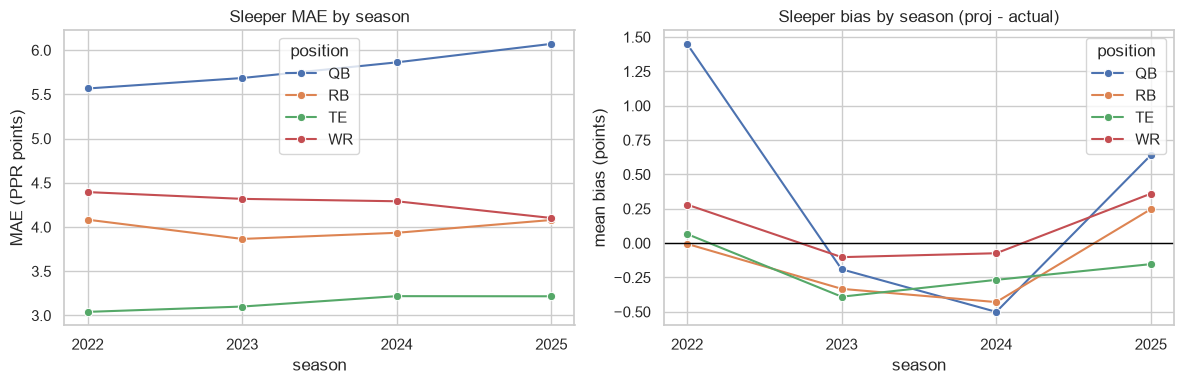

model     last4_avg  season_avg  sleeper
position                                
ALL           0.372       0.385    0.486
QB           -0.043      -0.022    0.161
RB            0.352       0.369    0.488
TE            0.265       0.293    0.387
WR            0.286       0.295    0.405


position,QB,RB,TE,WR
season,,,,
2022,1.450,-0.010,0.070,0.280
2023,-0.190,-0.330,-0.390,-0.100
2024,-0.500,-0.430,-0.270,-0.070
2025,0.640,0.250,-0.150,0.360


In [5]:
by_season = pd.DataFrame([{"season": s, "position": p, **metrics(g.proj, g.act)}
                          for (s, p), g in df.groupby(["season", "position"])])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(by_season, x="season", y="mae", hue="position", marker="o", ax=axes[0])
axes[0].set(title="Sleeper MAE by season", ylabel="MAE (PPR points)", xlabel="season")
sns.lineplot(by_season, x="season", y="bias", hue="position", marker="o", ax=axes[1])
axes[1].axhline(0, color="black", lw=1)
axes[1].set(title="Sleeper bias by season (proj - actual)", ylabel="mean bias (points)", xlabel="season")
axes[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True)); axes[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout(); plt.savefig(FIG / "01_mae_bias_by_season.png", dpi=120); plt.show()
print(acc.pivot(index="position", columns="model", values="r2").round(3))
by_season.pivot(index="season", columns="position", values="bias").round(2)

**Findings**


- On the same rows (2022-2025), Sleeper's MAE is **4.09** against 4.43 for the season-to-date average and 4.52
  for the last-4-games average: **8% better than the best naive baseline**. R2 is 0.49 against 0.39.
- **QB is the weak spot**: R2 0.16 (naive 0.0), MAE 5.79. QB scoring is driven by passing TDs and rushing, which
  are hard to project. RB is the strongest (R2 0.49).
- Bias moves by season: **QBs over-projected by 1.45 in 2022**, then -0.2 to +0.6. 2025 is over-projected at all
  positions except TE (+0.25 to +0.64). Since bias isn't stable across years, a global correction learned on old
  seasons won't carry forward reliably.

## 3. Calibration: when Sleeper says X points, what happens?

Binned mean actual vs. mean projection per position, and the calibration slope from `act ~ proj`
(slope < 1 means projections are too spread out: high projections too high, low ones too low).
Standard errors are clustered by player because the same player contributes many rows.

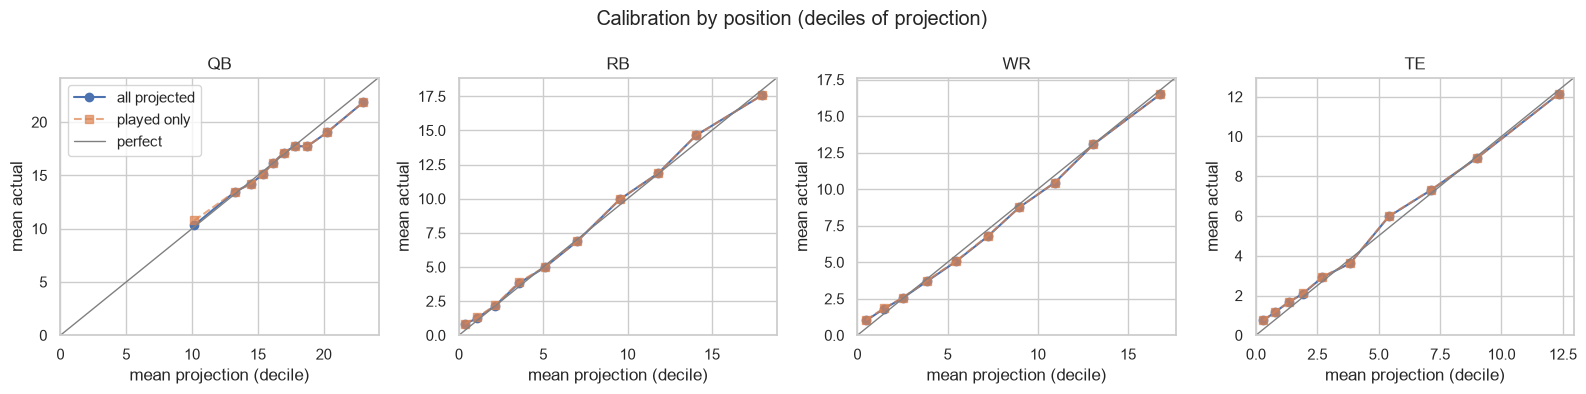

,position,intercept,slope,slope_lo,slope_hi
0,QB,1.411,0.894,0.804,0.985
1,RB,0.241,0.984,0.959,1.010
2,TE,0.372,0.956,0.912,1.000
3,WR,0.165,0.960,0.936,0.985


In [6]:
df["proj_bin"] = df.groupby("position").proj.transform(lambda s: pd.qcut(s, 10, labels=False, duplicates="drop"))
cal = df.groupby(["position", "proj_bin"]).agg(proj=("proj", "mean"), act=("act", "mean"),
                                               act_played=("act", lambda s: s[df.loc[s.index, "played"]].mean()),
                                               n=("act", "size")).reset_index()
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)
for ax, pos in zip(axes, POSITIONS):
    c = cal[cal.position == pos]
    ax.plot(c.proj, c.act, "o-", label="all projected")
    ax.plot(c.proj, c.act_played, "s--", alpha=.7, label="played only")
    lim = [0, c[["proj", "act"]].max().max() * 1.05]
    ax.plot(lim, lim, color="grey", lw=1, label="perfect")
    ax.set(title=pos, xlabel="mean projection (decile)", ylabel="mean actual", xlim=lim, ylim=lim)
axes[0].legend()
plt.suptitle("Calibration by position (deciles of projection)"); plt.tight_layout()
plt.savefig(FIG / "01_calibration.png", dpi=120); plt.show()

slopes = []
for pos, g in df.groupby("position"):
    r = smf.ols("act ~ proj", g).fit(cov_type="cluster", cov_kwds={"groups": g.player_id.astype("category").cat.codes})
    slopes.append({"position": pos, "intercept": r.params["Intercept"], "slope": r.params["proj"],
                   "slope_lo": r.conf_int().loc["proj", 0], "slope_hi": r.conf_int().loc["proj", 1]})
pd.DataFrame(slopes)

**Findings**


- RB, WR and TE are well calibrated (slopes 0.96-0.98, close to 1).
- **QB slope 0.89 (CI 0.80-0.99) with intercept 1.4**: the top QB projections are too high. QBs projected at
  about 19 points average about 17. Shrinking top-QB projections toward the mean is a small, defensible fix.
- The "all projected" and "played only" lines overlap, because Sleeper has already removed most non-players.

## 4. Bias by segment

Each segment variable is tested with `resid ~ C(segment)` (player-clustered SEs, Wald test that all levels
share one bias), with Benjamini-Hochberg correction across the segment variables. Effect size = the spread
between the most over- and most under-projected level, in points. Segments correlate with the projection
level (favorites have bigger projections), so a second multivariable model controls for projection and
position before judging any segment.

In [7]:
d = df.copy()

def cut(x, bins, labels=None):
    # ordered bins; missing values get their own 'unknown' level
    c = pd.cut(x, bins, labels=labels)
    if labels is None:
        c = c.cat.rename_categories(str)
    return c.cat.add_categories("unknown").fillna("unknown").cat.remove_unused_categories()

d["tier"] = cut(d.proj, [0, 3, 6, 10, 15, 20, 60])
d["week_bin"] = cut(d.week, [0, 1, 4, 9, 14, 17, 18], ["1", "2-4", "5-9", "10-14", "15-17", "18"])
d["spread_bin"] = cut(d.team_spread, [-30, -7, -3, 3, 7, 30], ["dog 7+", "dog 3-7", "close", "fav 3-7", "fav 7+"])
d["implied_bin"] = cut(d.implied_total, [0, 19, 22, 25, 50], ["<19", "19-22", "22-25", "25+"])
d["dome"] = d.roof.isin(["dome", "closed"]).map({True: "dome", False: "outdoor"})
d["windy"] = np.where(d.wind >= 15, "wind 15+", "calm/unknown")
d["exp_bin"] = cut(d.years_exp, [-1, 0, 1, 4, 30], ["rookie", "2nd yr", "3-5 yr", "6+ yr"])
d["age_bin"] = cut(d.age, [0, 24, 27, 30, 50], ["<24", "24-27", "27-30", "30+"])
d["rest_bin"] = cut(d.rest, [0, 5, 7, 20], ["short", "normal", "long/bye"])
d["questionable"] = np.where(d.report_status == "Questionable", "Q", "no tag")
d["home_s"] = d.home.map({1: "home", 0: "away"})
d["div"] = d.div_game.map({1: "division", 0: "non-division"})
d["cluster"] = d.player_id.astype("category").cat.codes
SEGMENTS = ["tier", "week_bin", "spread_bin", "implied_bin", "dome", "windy", "exp_bin", "age_bin",
            "rest_bin", "questionable", "home_s", "div", "position"]

def segment_test(data, seg):
    r = smf.ols(f"resid ~ C({seg})", data).fit(cov_type="cluster", cov_kwds={"groups": data.cluster})
    k = len(r.params)
    p = r.f_test(np.eye(k)[1:]).pvalue if k > 1 else np.nan
    lv = data.groupby(seg, observed=True).resid.agg(["mean", "size"])
    return {"segment": seg, "p": float(p), "spread_pts": lv["mean"].max() - lv["mean"].min(),
            "most_over": lv["mean"].idxmax(), "most_under": lv["mean"].idxmin()}

seg = pd.DataFrame([segment_test(d, s) for s in SEGMENTS])
seg["p_bh"] = multipletests(seg.p, method="fdr_bh")[1]
seg.sort_values("spread_pts", ascending=False)

,segment,p,spread_pts,most_over,most_under,p_bh
0,tier,0.000,1.317,"(20, 60]","(0, 3]",0.000
1,week_bin,0.000,0.974,1,5-9,0.000
9,questionable,0.000,0.842,Q,no tag,0.000
5,windy,0.000,0.565,wind 15+,calm/unknown,0.000
12,position,0.000,0.522,QB,TE,0.000
6,exp_bin,0.000,0.464,unknown,rookie,0.000
8,rest_bin,0.066,0.425,long/bye,short,0.071
2,spread_bin,0.008,0.402,dog 7+,fav 7+,0.011
3,implied_bin,0.048,0.330,<19,25+,0.063
7,age_bin,0.206,0.263,30+,<24,0.206


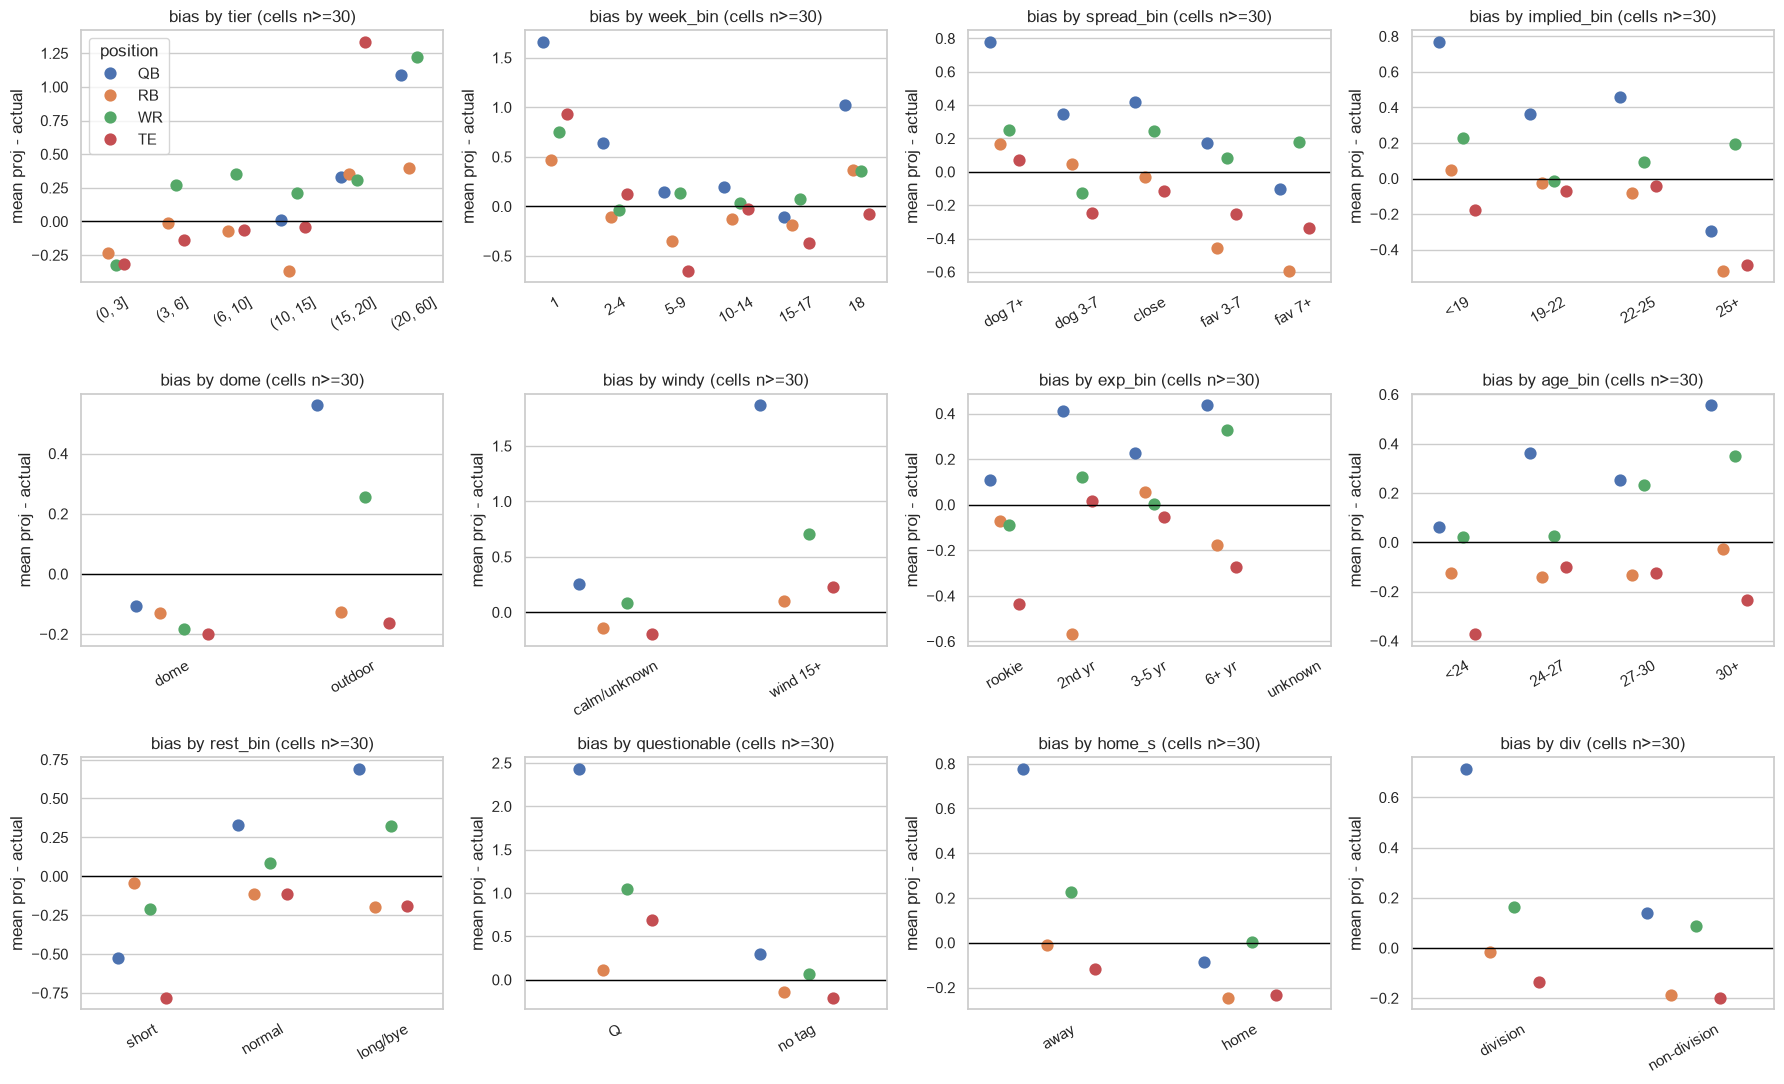

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, s in zip(axes.flat, [x for x in SEGMENTS if x != "position"]):
    lv = d.groupby([s, "position"], observed=True).resid.agg(["mean", "size"]).reset_index()
    lv = lv[lv["size"] >= 30]  # hide tiny cells
    sns.pointplot(lv, x=s, y="mean", hue="position", hue_order=POSITIONS, ax=ax, dodge=.4, linestyle="none", errorbar=None)
    ax.axhline(0, color="black", lw=1)
    ax.set(title=f"bias by {s} (cells n>=30)", xlabel="", ylabel="mean proj - actual")
    ax.tick_params(axis="x", rotation=30)
    if ax is not axes.flat[0]:
        ax.get_legend().remove()
plt.tight_layout(); plt.savefig(FIG / "01_bias_by_segment.png", dpi=120); plt.show()

In [9]:
mv = smf.ols("resid ~ proj + C(position) + C(week_bin) + C(spread_bin) + C(dome) + C(windy) + C(exp_bin) "
             "+ C(age_bin) + C(questionable) + C(home_s) + C(rest_bin)", d).fit(
    cov_type="cluster", cov_kwds={"groups": d.cluster})
coef = pd.DataFrame({"coef": mv.params, "lo": mv.conf_int()[0], "hi": mv.conf_int()[1], "p": mv.pvalues})
coef["p_bh"] = multipletests(coef.p, method="fdr_bh")[1]
print(f"R2 of the bias model: {mv.rsquared:.4f} (share of residual variance the segments explain)")
coef[coef.p_bh < 0.05].sort_values("coef")

R2 of the bias model: 0.0067 (share of residual variance the segments explain)


,coef,lo,hi,p,p_bh
C(week_bin)[T.5-9],-1.053,-1.387,-0.720,0.000,0.000
C(week_bin)[T.15-17],-1.001,-1.355,-0.647,0.000,0.000
C(week_bin)[T.10-14],-0.871,-1.208,-0.533,0.000,0.000
C(questionable)[T.no tag],-0.810,-1.164,-0.455,0.000,0.000
C(week_bin)[T.2-4],-0.792,-1.129,-0.455,0.000,0.000
C(week_bin)[T.18],-0.542,-0.945,-0.139,0.008,0.016
C(spread_bin)[T.fav 7+],-0.394,-0.702,-0.085,0.012,0.022
C(spread_bin)[T.fav 3-7],-0.367,-0.641,-0.094,0.008,0.016
C(spread_bin)[T.dog 3-7],-0.325,-0.558,-0.092,0.006,0.014
C(home_s)[T.home],-0.230,-0.368,-0.093,0.001,0.004


**Findings**


Biases that survive BH correction **and** the multivariable controls (proj - actual, points per game):
- **Week 1: about +1.0 point over-projection** compared with weeks 5-17 (coefficients -0.8 to -1.05). Projections
  for the opener lean on preseason priors that turn out too optimistic.
- **Questionable tag: +0.81** compared with untagged players. Sleeper keeps Q players at full value, but they
  under-deliver even when they play (the bias is measured on games played).
- **Wind 15+ mph: +0.53**, and **outdoor games +0.23** compared with domes. Weather is only partly priced in.
- **Away +0.23** compared with home. **Big underdogs (7+)** are over-projected compared with every other spread bin
  (+0.33 to +0.39).
- After a **bye or long rest: +0.41**.
- Tier: the bias grows with projection (+0.036 per projected point). High projections are slightly too high,
  consistent with calibration.

**Size check:** all the segment terms together explain **0.7% of the residual variance**. The biases are real
but small next to game-to-game noise (SD of about 5.5 points), so correcting them can only buy a few percent of
MAE. The rest is irreducible noise for any pre-game model.

## 5. Which stat drives the error?

The projected and actual stat lines are both available, so each component's contribution to the
fantasy-point error can be measured (PPR weights). Share of error variance per component =
Cov(component error, total error) / Var(total error); these shares sum to ~1. Played games only, so
availability errors don't hide the stat-line errors.

component errors reproduce the total residual: corr=0.9990


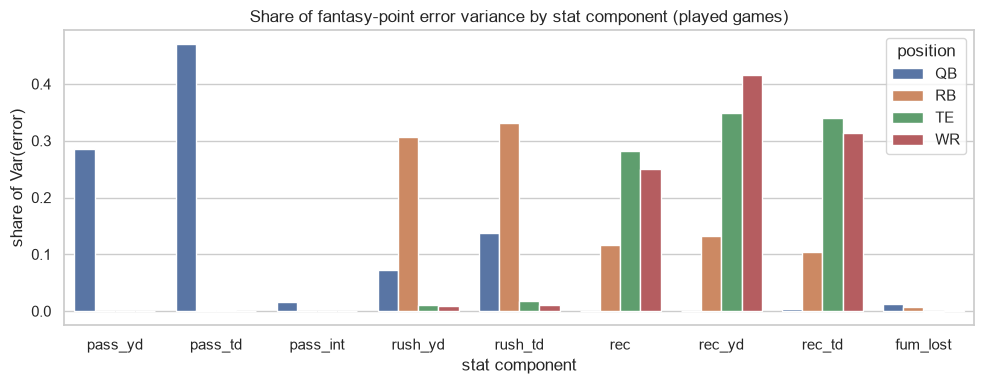

position,QB,RB,TE,WR
component,,,,
fum_lost,-0.052,0.011,0.006,0.004
pass_int,-0.077,0.000,0.000,0.001
pass_td,0.437,-0.006,-0.001,-0.004
pass_yd,0.168,-0.001,-0.001,-0.001
rec,-0.012,-0.063,-0.110,0.003
rec_td,-0.016,0.008,0.024,0.104
rec_yd,-0.002,-0.035,-0.075,0.017
rush_td,-0.092,0.033,-0.017,-0.021
rush_yd,0.000,-0.093,-0.009,0.001


In [10]:
W = {"pass_yd": .04, "pass_td": 4, "pass_int": -1, "rush_yd": .1, "rush_td": 6, "rec": 1, "rec_yd": .1,
     "rec_td": 6, "fum_lost": -2}
pl = df[df.played].copy()
for c, w in W.items():
    pl[f"e_{c}"] = w * (pl[f"proj_{c}"] - pl[f"act_{c}"])
pl["e_sum"] = pl[[f"e_{c}" for c in W]].sum(axis=1)
print(f"component errors reproduce the total residual: corr={pl.e_sum.corr(pl.resid):.4f}")
rows = []
for pos, g in pl.groupby("position"):
    v = g.e_sum.var()
    for c in W:
        if g[f"proj_{c}"].abs().sum() == 0 and g[f"act_{c}"].abs().sum() == 0:
            continue
        rows.append({"position": pos, "component": c, "bias_pts": g[f"e_{c}"].mean(),
                     "share_of_error_var": np.cov(g[f"e_{c}"], g.e_sum)[0, 1] / v})
comp = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(comp, x="component", y="share_of_error_var", hue="position", ax=ax)
ax.set(title="Share of fantasy-point error variance by stat component (played games)",
       ylabel="share of Var(error)", xlabel="stat component")
plt.tight_layout(); plt.savefig(FIG / "01_error_components.png", dpi=120); plt.show()
comp.pivot(index="component", columns="position", values="bias_pts").round(3)

In [11]:
# Volume vs efficiency: are the opportunity counts (targets, carries, attempts) projected without bias?
vol = pl.groupby("position")[["proj_rec_tgt", "act_rec_tgt", "proj_rush_att", "act_rush_att", "proj_pass_att", "act_pass_att"]].mean()
vol

,proj_rec_tgt,act_rec_tgt,proj_rush_att,act_rush_att,proj_pass_att,act_pass_att
position,,,,,,
QB,0.000,0.015,3.764,3.886,31.951,31.287
RB,1.873,1.929,7.303,7.437,0.000,0.004
TE,2.571,2.640,0.044,0.072,0.006,0.008
WR,4.047,4.030,0.177,0.171,0.001,0.006


**Findings**


- The stat-line errors reproduce the total residual (corr 0.999), so the decomposition is exact enough to trust.
- **QB: passing TDs (+0.44 points per game) and passing yards (+0.17) are over-projected.** QB attempts are
  projected at 31.95 against 31.29 actual. That is a passing-volume and passing-TD optimism, not a rushing issue.
- **WR: receiving TDs are over-projected (+0.10 points per game)**, while receptions and yards are on target.
  Touchdowns are the noisiest stat and the one Sleeper is most optimistic about.
- **RB/TE are slightly under-projected on volume** (RB carries 7.30 vs 7.44, TE targets 2.57 vs 2.64).
- Where the error variance comes from (`figures/01_error_components.png`): **QB**: passing TDs 47%, passing
  yards 28%, rushing TDs 14%. **RB**: rushing TDs 33% and rushing yards 31%. **WR**: receiving yards 41%,
  receiving TDs 31%, receptions 25%. **TE**: receiving yards 35%, receiving TDs 34%, receptions 28%.
  Touchdowns are a third to a half of the error everywhere, and they are close to unpredictable game to game.

## 6. Ranking quality: does Sleeper order players correctly?

Fantasy decisions are relative (start A or B), so ordering matters more than absolute error. Within each
position-week, among players projected at least 5 points: Spearman correlation between projection and
actual, and the pairwise hit rate: how often the higher-projected player outscored the other, by gap size.

mean within-week Spearman by position:
position
QB   0.362
RB   0.524
TE   0.336
WR   0.472
dtype: float64


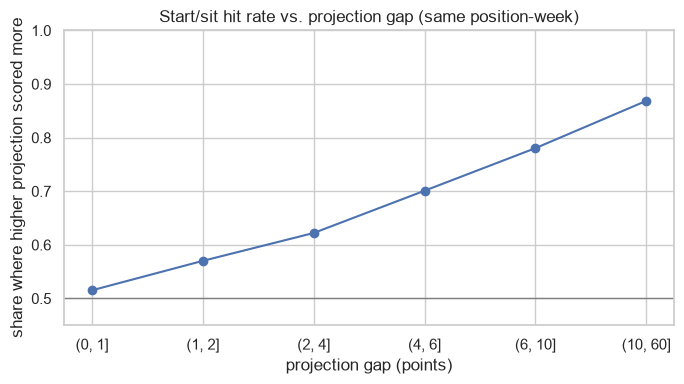

,mean,size
gap_bin,,
"(0, 1]",0.515,60699
"(1, 2]",0.570,55275
"(2, 4]",0.622,93049
"(4, 6]",0.701,69901
"(6, 10]",0.780,74447
"(10, 60]",0.869,24485


In [12]:
rel = df[df.proj >= 5]
sp = rel.groupby(["season", "week", "position"]).apply(lambda g: stats.spearmanr(g.proj, g.act)[0] if len(g) > 5 else np.nan,
                                                        include_groups=False)
print("mean within-week Spearman by position:")
print(sp.groupby(level="position").mean().round(3))

rng = np.random.default_rng(0)
pairs = []
for _, g in rel.groupby(["season", "week", "position"]):
    if len(g) < 2:
        continue
    i, j = np.triu_indices(len(g), 1)
    p, a = g.proj.to_numpy(), g.act.to_numpy()
    pairs.append(pd.DataFrame({"gap": np.abs(p[i] - p[j]), "hit": np.sign(p[i] - p[j]) == np.sign(a[i] - a[j])}))
pairs = pd.concat(pairs)
pairs["gap_bin"] = pd.cut(pairs.gap, [0, 1, 2, 4, 6, 10, 60])
hit = pairs.groupby("gap_bin", observed=True).hit.agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hit.index.astype(str), hit["mean"], "o-")
ax.axhline(.5, color="grey", lw=1)
ax.set(title="Start/sit hit rate vs. projection gap (same position-week)", xlabel="projection gap (points)",
       ylabel="share where higher projection scored more", ylim=(.45, 1))
plt.tight_layout(); plt.savefig(FIG / "01_pairwise_hit_rate.png", dpi=120); plt.show()
hit

**Findings**


- Mean within-week Spearman for players projected 5+: RB 0.52, WR 0.47, QB 0.36, TE 0.34.
- **Start/sit hit rate:** when two same-position players are within 1 point of each other, the higher projection
  wins **51.5%** of the time, a coin flip. Within 2-4 points it is 62%, and only a 10+ point gap reaches 87%. Close
  calls between Sleeper projections are not decisions Sleeper can make for you.

## 7. Recurring player-level bias: is it persistent or just noise?

Some players will always look over- or under-projected in a finite sample. The question that matters is
whether it repeats: does a player's mean residual in season t predict it in season t+1? Residuals are taken
relative to the position-season mean (`resid_rel`), otherwise a position-wide bias (e.g. all QBs in 2022)
shows up as hundreds of "player" biases. Then a per-player t-test across all games (>= 30 games,
BH-corrected) lists the players with a significant recurring bias.

player-season mean residual, t vs t+1: r=-0.112 (p=0.02, n=437 player-season pairs)
position
QB   -0.303
RB   -0.180
TE    0.083
WR   -0.053
dtype: float64


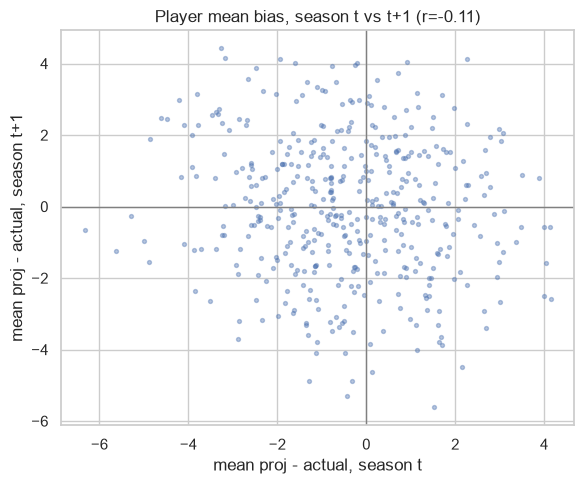

In [13]:
df["resid_rel"] = df.resid - df.groupby(["season", "position"]).resid.transform("mean")
ps = df[df.played & (df.proj >= 5)].groupby(["player_id", "season"]).agg(
    name=("name", "first"), position=("position", "first"), resid=("resid_rel", "mean"), n=("resid", "size")).reset_index()
ps = ps[ps.n >= 8]
nxt = ps.assign(season=ps.season - 1)[["player_id", "season", "resid"]]
pers = ps.merge(nxt, on=["player_id", "season"], suffixes=("", "_next"))
r, p = stats.pearsonr(pers.resid, pers.resid_next)
print(f"player-season mean residual, t vs t+1: r={r:.3f} (p={p:.2g}, n={len(pers)} player-season pairs)")
print(pers.groupby("position").apply(lambda g: g.resid.corr(g.resid_next), include_groups=False).round(3))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(pers.resid, pers.resid_next, s=8, alpha=.4)
ax.axhline(0, color="grey", lw=1); ax.axvline(0, color="grey", lw=1)
ax.set(title=f"Player mean bias, season t vs t+1 (r={r:.2f})", xlabel="mean proj - actual, season t",
       ylabel="mean proj - actual, season t+1")
plt.tight_layout(); plt.savefig(FIG / "01_player_bias_persistence.png", dpi=120); plt.show()

In [14]:
pg = df[df.played & (df.proj >= 5)].groupby("player_id").agg(
    name=("name", "first"), position=("position", "first"), n=("resid", "size"),
    bias=("resid_rel", "mean"), sd=("resid_rel", "std"))
pg = pg[pg.n >= 30].copy()
pg["p"] = 2 * stats.t.sf(np.abs(pg.bias / (pg.sd / np.sqrt(pg.n))), pg.n - 1)
pg["p_bh"] = multipletests(pg.p, method="fdr_bh")[1]
print(f"{(pg.p_bh < .05).sum()} of {len(pg)} players with >=30 games have a significant recurring bias (BH 5%)")
pg[pg.p_bh < .05].sort_values("bias")

0 of 187 players with >=30 games have a significant recurring bias (BH 5%)


,name,position,n,bias,sd,p,p_bh
player_id,,,,,,,


**Findings**


- After removing the position-season mean, **no player shows a significant recurring bias** (0 of 187 players
  with 30+ games at BH 5%). Before demeaning (first run), 18 QBs looked significant. That was the QB-wide gap from
  1b and the 2022 QB bias, not anything player-specific.
- Season-to-season persistence of a player's bias is **slightly negative** (r = -0.11, p = 0.02, one test, n = 437
  pairs; QB -0.30, RB -0.18). A player Sleeper over-projected last year tends to be a bit under-projected this year,
  which suggests over-correction between seasons. It is weak evidence, and a per-player correction is not supported.

## 8. Does Sleeper under-react to recent form?

If Sleeper's recent misses for a player predict its next miss, the projection is slow to update, and that is
something a model can exploit. `trail_resid3` = the player's mean residual over his previous 3 played games.

In [15]:
m = df[df.played & df.trail_resid3.notna() & (df.proj >= 3)]
rows = []
for pos, g in m.groupby("position"):
    r = smf.ols("resid ~ trail_resid3", g).fit(cov_type="cluster", cov_kwds={"groups": g.player_id.astype("category").cat.codes})
    rows.append({"position": pos, "coef": r.params["trail_resid3"], "lo": r.conf_int().loc["trail_resid3", 0],
                 "hi": r.conf_int().loc["trail_resid3", 1], "r2": r.rsquared, "n": len(g)})
pd.DataFrame(rows)

,position,coef,lo,hi,r2,n
0,QB,0.097,0.032,0.162,0.003,2064
1,RB,0.050,0.002,0.099,0.001,4223
2,TE,0.009,-0.057,0.075,0.000,2842
3,WR,0.007,-0.034,0.048,0.000,6887


**Findings**


- Sleeper's misses over a player's previous 3 games predict the next miss only for **QBs (coefficient 0.10, R2
  0.3%)** and barely for RBs (0.05). WR and TE show nothing.
- Sleeper adjusts to recent form about as fast as the data allows. Recent residuals are a weak feature at most.

## 9. Availability: projected players who did not play

A projected player who never takes the field scores 0, the costliest miss a manager can suffer. How often
does it happen, and does the injury tag carry information Sleeper's number does not?

In [16]:
av = df.assign(dnp=~df.played)
print(f"projected players who did not play: {av.dnp.mean():.2%} of rows, "
      f"{av.loc[av.dnp, 'proj'].sum() / av.proj.sum():.2%} of all projected points")
print(av.groupby("season").dnp.mean().round(4))
t = av.groupby("report_status").agg(dnp_rate=("dnp", "mean"), n=("dnp", "size"), mean_proj=("proj", "mean"),
                                    bias_played=("resid", lambda s: s[av.loc[s.index, "played"]].mean()))
t

projected players who did not play: 0.88% of rows, 0.22% of all projected points
season
2022   0.008
2023   0.007
2024   0.008
2025   0.011
Name: dnp, dtype: float64


,dnp_rate,n,mean_proj,bias_played
report_status,,,,
None,0.009,23110,7.348,-0.048
Note,0.000,2,8.168,-4.142
Out,1.000,1,0.530,NaN
Questionable,0.010,1055,8.404,0.792


In [17]:
# Played but few snaps: partial games (in-game injury, benching) by projection tier
av["low_snaps"] = av.played & (av.off_snp < 0.25 * av.tm_off_snp)
av.assign(tier=pd.cut(av.proj, [0, 5, 10, 15, 60])).groupby("tier", observed=True)[["dnp", "low_snaps"]].mean()

,dnp,low_snaps
tier,,
"(0, 5]",0.019,0.521
"(5, 10]",0.003,0.095
"(10, 15]",0.000,0.019
"(15, 60]",0.000,0.011


In [18]:
# The reverse miss: players Sleeper projected at 0 (or not at all) who then played and scored.
# These rows are outside the analysis universe (proj > 0), so they never show up in the error metrics.
from common import score
a_sk = a_raw[a_raw.player_position.isin(POSITIONS) & a_raw.season.between(2021, 2025) & a_raw.gp.eq(1)].copy()
a_sk["act"] = score(a_sk.reindex(columns=a_sk.columns.union(SCORING.keys())).fillna(0), "")
p_sk = p_raw[["player_id", "season", "week"]].assign(proj=score(p_raw.reindex(columns=p_raw.columns.union(SCORING.keys())).fillna(0), ""))
z = a_sk.merge(p_sk, on=["player_id", "season", "week"], how="left")
z["proj"] = z.proj.fillna(0)
big = z[z.act >= 10]
print(big.assign(zero=big.proj == 0).groupby("season").zero.agg(["sum", "mean"]).rename(columns={"sum": "10+ pt games projected 0", "mean": "share"}))
print(big[big.proj == 0].nlargest(5, "act")[["season", "week", "player_first_name", "player_last_name", "player_position", "act"]].to_string(index=False))

C:\Users\Or\AppData\Local\Temp\ipykernel_3936\387785069.py:5: Pandas4Warning: 'int' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  a_sk["act"] = score(a_sk.reindex(columns=a_sk.columns.union(SCORING.keys())).fillna(0), "")


C:\Users\Or\AppData\Local\Temp\ipykernel_3936\387785069.py:6: Pandas4Warning: 'int' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  p_sk = p_raw[["player_id", "season", "week"]].assign(proj=score(p_raw.reindex(columns=p_raw.columns.union(SCORING.keys())).fillna(0), ""))


        10+ pt games projected 0  share
season                                 
2021                          63  0.032
2022                          21  0.011
2023                          19  0.011
2024                          16  0.009
2025                           8  0.004
 season  week player_first_name player_last_name player_position    act
   2021     5               Tom            Brady              QB 37.740
   2021     5           Antonio            Brown              WR 31.400
   2021    14               Tom            Brady              QB 30.120
   2021     2               Tom            Brady              QB 29.640
   2021    13               Tom            Brady              QB 29.620


**Findings**


- Only **0.88% of projected players did not play** (0.22% of projected points). Sleeper's late snapshot removes
  almost all inactive players, so availability is not where Sleeper loses accuracy.
- **Partial games** are a bigger factor: 9.5% of players projected 5-10 points played under a quarter of their team's
  snaps. In-game injuries and benchings are invisible pre-game.
- **The reverse miss (projected 0, scored 10+)** is rare in 2022-2025 (0.4-1.1% of 10+ point games). In **2021 it is
  3.2%, concentrated in players who retired or left soon after** (Brady, Roethlisberger, A. Brown, Ruggs). Their
  2021 projections are empty, which is survivorship in the stored data and the reason 2021 is excluded here.

## 10. Error distribution, and what it means for the loss

Fantasy points are right-skewed (a few huge games), so the error distribution is skewed too. A projection
that targets the mean is the right choice for RMSE but not for MAE, which is minimized by the median. Scaling
Sleeper's projection by k shows which target Sleeper optimizes.

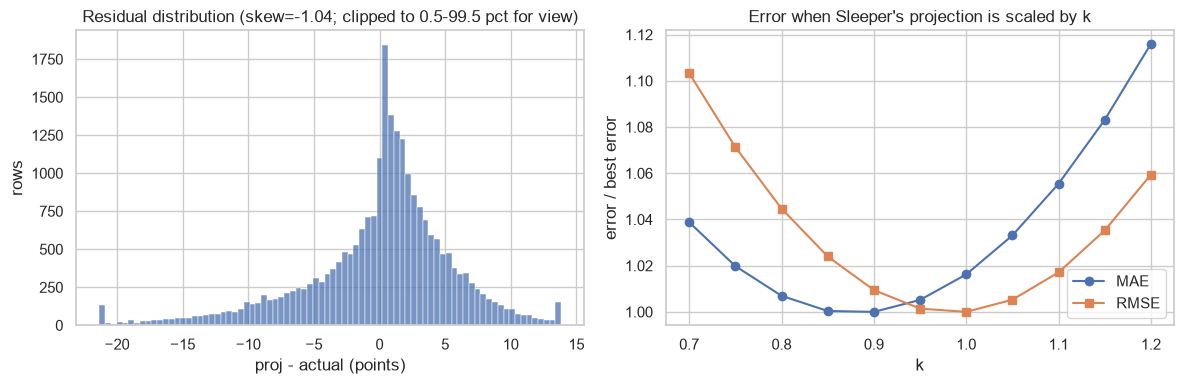

best k for MAE: 0.9  best k for RMSE: 1.0
median actual / median projection: 4.70 / 6.19


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
lo, hi = df.resid.quantile([.005, .995])
sns.histplot(df.resid.clip(lo, hi), bins=80, ax=axes[0])
axes[0].set(title=f"Residual distribution (skew={df.resid.skew():.2f}; clipped to 0.5-99.5 pct for view)",
            xlabel="proj - actual (points)", ylabel="rows")
ks = np.round(np.arange(.7, 1.21, .05), 2)
sc = pd.DataFrame([{"k": k, "mae": (k * df.proj - df.act).abs().mean(), "rmse": np.sqrt(((k * df.proj - df.act) ** 2).mean())} for k in ks])
axes[1].plot(sc.k, sc.mae / sc.mae.min(), "o-", label="MAE")
axes[1].plot(sc.k, sc.rmse / sc.rmse.min(), "s-", label="RMSE")
axes[1].set(title="Error when Sleeper's projection is scaled by k", xlabel="k", ylabel="error / best error")
axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "01_residual_distribution.png", dpi=120); plt.show()
print("best k for MAE:", sc.loc[sc.mae.idxmin(), "k"], " best k for RMSE:", sc.loc[sc.rmse.idxmin(), "k"])
print(f"median actual / median projection: {df.act.median():.2f} / {df.proj.median():.2f}")

**Findings**


- Residuals are skewed, and actual points are right-skewed: the median actual is 4.70 against a median projection
  of 6.19. Sleeper projects a **mean**.
- Scaling Sleeper by k: RMSE is best at **k = 1.0** (Sleeper is mean-unbiased overall), MAE is best at **k = 0.9**.
- **Pitfall for task 3:** a model trained with an absolute-error loss will "beat" Sleeper on MAE just by predicting
  the median. That is a loss choice, not skill. `03_model` reports MAE and RMSE and compares against Sleeper x k*
  with k fit on training seasons, as well as raw Sleeper.

## 11. Anomalies

The largest misses, and weeks where Sleeper's error was unusually high (league-wide events such as
week-18 rest days or COVID outbreaks).

In [20]:
print("largest over-projections (busts):")
print(df.nlargest(8, "resid")[["season", "week", "name", "position", "proj", "act", "played", "off_snp", "report_status"]].to_string(index=False))
print("\nlargest under-projections (booms):")
print(df.nsmallest(8, "resid")[["season", "week", "name", "position", "proj", "act", "off_snp"]].to_string(index=False))

largest over-projections (busts):
 season  week              name position   proj   act  played  off_snp report_status
   2022    13     Lamar Jackson       QB 23.887 1.340    True   10.000          None
   2022    17  Justin Jefferson       WR 24.419 2.500    True   46.000          None
   2023    18       Jalen Hurts       QB 22.566 1.600    True   28.000          None
   2025     3       CeeDee Lamb       WR 20.397 0.000    True    7.000          None
   2025    18      Dak Prescott       QB 20.390 0.700    True    0.000          None
   2025    13 Amon-Ra St. Brown       WR 19.187 0.000    True    4.000          None
   2022    14      Kyler Murray       QB 19.496 0.660    True    3.000          None
   2022     3  Justin Jefferson       WR 22.983 4.400    True   72.000          None

largest under-projections (booms):
 season  week           name position   proj    act  off_snp
   2023     3  De'Von Achane       RB  4.934 51.300   30.000
   2022     9      Joe Mixon       RB 16.96

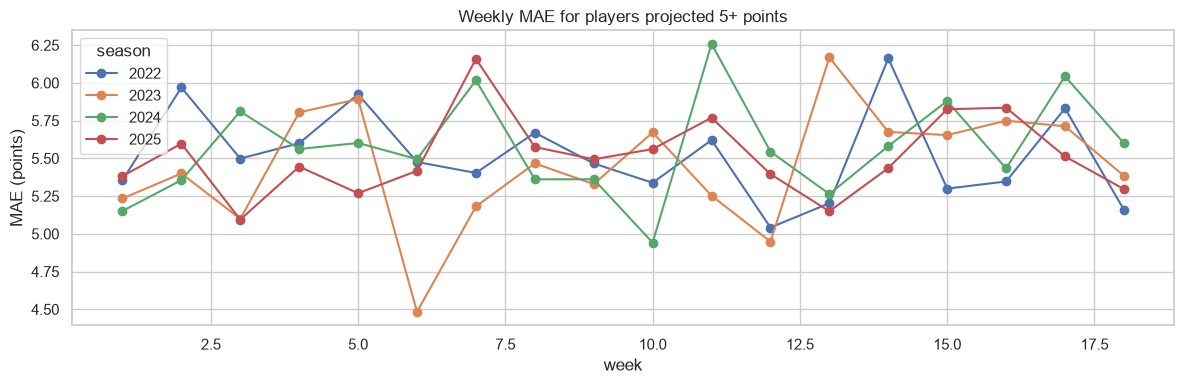

,season,week,mae,bias,dnp,z
46,2024,11,6.258,-1.218,0.000,2.319
30,2023,13,6.169,-1.187,0.000,2.041
13,2022,14,6.163,0.344,0.000,2.021
60,2025,7,6.159,0.321,0.000,2.010
52,2024,17,6.044,-0.896,0.000,1.651
42,2024,7,6.017,0.829,0.000,1.567


In [21]:
wk = df[df.proj >= 5].groupby(["season", "week"]).agg(mae=("resid", lambda s: s.abs().mean()), bias=("resid", "mean"),
                                                     dnp=("played", lambda s: 1 - s.mean())).reset_index()
wk["z"] = (wk.mae - wk.mae.mean()) / wk.mae.std()
fig, ax = plt.subplots(figsize=(12, 4))
for s, g in wk.groupby("season"):
    ax.plot(g.week, g.mae, "o-", label=s)
ax.set(title="Weekly MAE for players projected 5+ points", xlabel="week", ylabel="MAE (points)")
ax.legend(title="season"); plt.tight_layout(); plt.savefig(FIG / "01_weekly_mae.png", dpi=120); plt.show()
wk.sort_values("z", ascending=False).head(6)

**Findings**


- **Biggest busts are in-game injuries or rest days**, not bad projections: Lamar Jackson 2022 wk13 (10 snaps),
  CeeDee Lamb 2025 wk3 (7 snaps), Dak Prescott 2025 wk18 (0 offensive snaps, rested). No pre-game model can
  predict these. Week 18 is a known rest-risk week.
- **Biggest booms** are mostly low-projected players breaking out (De'Von Achane 2023 wk3: 4.9 projected, 51.3
  actual; Tre Tucker 2025 wk3: 5.0 projected, 40.9 actual).
- **Shocks hit whole weeks:** in 2024 wk11 and 2023 wk13, every player was under-projected by about 1.2 points.
  Errors are correlated within a week. Any significance test in `03_model` must account for that (paired test on
  week-level mean errors), otherwise p-values are far too optimistic.
- **Data anomalies found and handled:** the QB `pts_ppr` gap (1b), the cancelled BUF-CIN 2022 wk17 game (dropped:
  Josh Allen scored 2.7 against 27.7 projected), `draft_year = 0` sentinels (set to missing), the 2021
  missing-projection hole, and Sleeper's `player_*` columns being today's metadata (not used).

## Summary


1. **Sleeper is a strong baseline**: MAE 4.09 and R2 0.49 for 2022-2025, 8% better than a season-average baseline.
   Most of the remaining error is game-to-game noise (TDs, in-game injuries, booms).
2. **Recurring biases (small but significant):** week 1 (+1.0), Questionable tag (+0.8), wind 15+ (+0.5),
   bye/long rest (+0.4), big underdogs (+0.35), away and outdoor games (+0.2), and high projections slightly too
   high (QB calibration slope 0.89).
3. **Underperforming sectors:** QBs (R2 0.16; passing TDs and yards over-projected), WR touchdowns, and close
   start/sit calls (under 1 point is a coin flip).
4. **No player-specific bias** survives correct testing, and persistence across seasons is slightly negative.
5. **Data pitfalls:** stored QB `pts_ppr` is inconsistent with the stat line (2021-2025), 2021 projections have a
   survivorship hole, the snapshot already knows Friday injuries and inactives, `player_*` metadata is current
   rather than point-in-time, and errors are correlated within a week.

**What this means for the model:** the model does **not** use Sleeper's (or anyone's) weekly projection as an input.
A model fed the projection learns to copy it, biases included. Sleeper is the benchmark only. The segments above
(week of season, injury tag, venue, spread, rest) are where an independent model can win, and they are all
available as plain pre-game facts. The comparison must be honest about Sleeper's edge: its final snapshot knows
game-day inactives (it zeroes almost every player who ends up not playing), which no pre-game fact feed has.
Score on the same rows, with MAE and RMSE, with week-clustered tests, and separately on players who played.